In [ ]:
import os, math, random, heapq, time, json, warnings, zlib
from collections import deque
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ------------------------- USER SETTINGS -------------------------
QUICK = False
ALIBABA_POD_CSV  = "/content/openb_pod_list_default.csv"
ALIBABA_NODE_CSV = "/content/openb_node_list_all_node.csv/content/openb_node_list_all_node.csv"
EM_DIR           = "/content/sample_data/electricitymaps"
REGIONS  = ["CN", "FR", "US-CA"]            # Electricity Maps zone codes
REGION_W = [0.50, 0.25, 0.25]                         # share of nodes per region (proportional mapping)
N_NODES      = 16                 # nodes simulated (sub-sampled from trace)
N_JOBS       = 500 if QUICK else 800
UTIL_TARGET  = 0.65               # arrival times are rescaled so offered load ~ this utilisation
MAX_DEFER    = 6                  # max 1-hour deferrals for deferrable jobs
PUE, UTIL_FACTOR = 1.2, 0.8
EPISODES = 40 if QUICK else 200
SEEDS    = [0] if QUICK else [0, 1, 2]
N_EVAL   = 4 if QUICK else 8
SEED = 42
np.random.seed(SEED); random.seed(SEED)

# GPU model -> (TDP watts, relative speed vs V100)
GPU_PROFILES = {"V100": (300, 1.0), "A100": (400, 2.2), "T4": (70, 0.45), "P100": (250, 0.7), "A10": (150, 1.1)}
MODEL_NAMES  = list(GPU_PROFILES)
print("Settings OK")

Settings OK


## 1. Data loading

Alibaba jobs: 6203


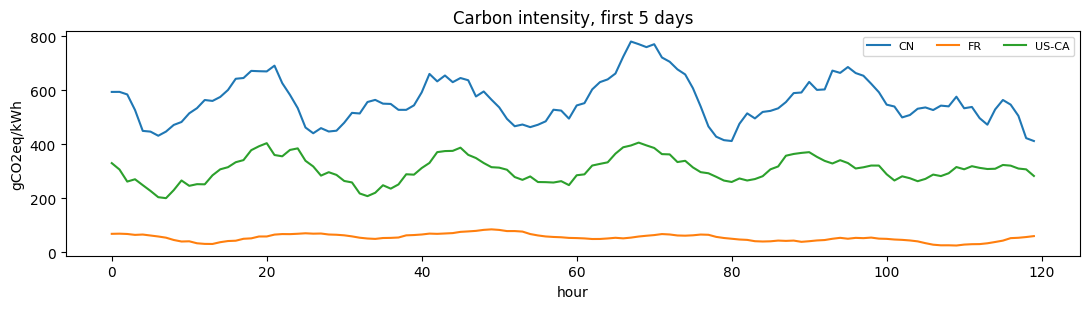

In [ ]:
rng_data = np.random.default_rng(SEED)

def map_model_name(s):
    s = str(s).upper()
    for k in MODEL_NAMES:
        if s.startswith(k): return k
    return MODEL_NAMES[zlib.crc32(s.encode()) % len(MODEL_NAMES)]          # G1/G2/G3 etc. -> deterministic bucket

def load_alibaba_jobs(path):
    df = pd.read_csv(path)
    df = df[(df["num_gpu"] >= 1) & (df["gpu_milli"] > 0)].copy()
    df["dur"] = df["deletion_time"] - df["scheduled_time"]
    df = df.dropna(subset=["creation_time", "dur"]); df = df[df["dur"] > 0]
    jobs = pd.DataFrame({"arr": df["creation_time"].astype(float), "dur": df["dur"].clip(60, 12 * 3600).astype(float),
                         "k": df["num_gpu"].clip(1, 8).astype(int), "m": df["gpu_milli"].clip(1, 1000).astype(int)})
    if "qos" in df.columns:
        jobs["defer"] = df["qos"].astype(str).isin(["BE", "Burstable"]).values
    if "defer" not in jobs or not (0.1 < jobs["defer"].mean() < 0.9):
        jobs["defer"] = rng_data.random(len(jobs)) < 0.5       # documented assumption
    return jobs.sort_values("arr").reset_index(drop=True)

def synth_jobs(n=20000):
    k = rng_data.choice([1, 2, 4, 8], size=n, p=[0.72, 0.10, 0.10, 0.08])
    m = np.where(k == 1, rng_data.choice([250, 500, 750, 1000], size=n, p=[0.2, 0.3, 0.1, 0.4]), 1000)
    dur = np.clip(rng_data.lognormal(mean=math.log(5400), sigma=1.1, size=n), 60, 12 * 3600)
    arr = np.cumsum(rng_data.exponential(30.0, size=n))
    return pd.DataFrame({"arr": arr, "dur": dur, "k": k, "m": m, "defer": rng_data.random(n) < 0.5})

def load_alibaba_nodes(path):
    df = pd.read_csv(path)
    gcol = "gpu" if "gpu" in df.columns else [c for c in df.columns if "gpu" in c.lower()][0]
    mcol = "model" if "model" in df.columns else None
    out = pd.DataFrame({"g": df[gcol].clip(1, 8).astype(int)})
    out["model"] = df[mcol].map(map_model_name) if mcol else rng_data.choice(MODEL_NAMES, size=len(df))
    return out

def synth_nodes(n=200):
    return pd.DataFrame({"g": rng_data.choice([8, 4, 2], size=n, p=[0.7, 0.2, 0.1]),
                         "model": rng_data.choice(MODEL_NAMES, size=n, p=[0.3, 0.15, 0.25, 0.15, 0.15])})

def load_em_zone(zone, d):
    for f in sorted(os.listdir(d)) if os.path.isdir(d) else []:
        if f.startswith(zone + "_") and f.endswith(".csv"):
            df = pd.read_csv(os.path.join(d, f))
            cols = [c for c in df.columns if "ntensity" in c and "arbon" in c]
            col = next((c for c in cols if "LCA" in c), cols[0])
            return df[col].astype(float).ffill().bfill().values
    return None

SYN_CI = {"CN": (560, .12, 14), "FR": (55, .25, 19), "DE": (380, .30, 13), "US-CAL-CISO": (230, .45, 15), "SE-SE3": (28, .20, 18)}
def synth_ci(zone, hours=24 * 120):
    base, amp, ph = SYN_CI.get(zone, (300, .2, 14))
    h = np.arange(hours); x = np.zeros(hours); e = rng_data.normal(0, 1, hours)
    for i in range(1, hours): x[i] = 0.9 * x[i - 1] + e[i]                       # AR(1) weather-like noise
    weekly = 1 + 0.08 * np.sin(2 * np.pi * h / 168)
    ci = base * (1 + amp * np.sin(2 * np.pi * (h - ph) / 24)) * weekly + base * 0.05 * x
    if zone == "US-CAL-CISO": ci -= base * 0.25 * np.exp(-((h % 24 - 13) ** 2) / 8)  # midday solar dip
    return np.clip(ci, 8, None)

# ---- jobs / nodes
if os.path.exists(ALIBABA_POD_CSV):  jobs_all = load_alibaba_jobs(ALIBABA_POD_CSV); print("Alibaba jobs:", len(jobs_all))
else:                                jobs_all = synth_jobs();                      print("[synthetic jobs]", len(jobs_all))
if os.path.exists(ALIBABA_NODE_CSV): nodes_all = load_alibaba_nodes(ALIBABA_NODE_CSV); print("Alibaba nodes:", len(nodes_all))


# ---- carbon intensity (hourly), aligned to the shortest series
ci_list, src = [], []

fig, ax = plt.subplots(figsize=(11, 3.2))
for i, z in enumerate(REGIONS): ax.plot(CI[i, :24 * 5], label=z)
ax.set_xlabel("hour"); ax.set_ylabel("gCO2eq/kWh"); ax.set_title("Carbon intensity, first 5 days"); ax.legend(ncol=5, fontsize=8); plt.tight_layout(); plt.show()

## 2. Region mapping & heterogeneous cluster
The Alibaba trace has no geography, so we map nodes to regions with an explicit, reproducible rule. Several strategies are provided so the **sensitivity analysis** (Section 10) can show results do not hinge on one arbitrary assignment.

In [ ]:
REGIONS = ["CN", "FR", "US-CA"]

REGION_W = [0.40, 0.30, 0.30]
def assign_regions(models, strategy, rng):
    n, R = len(models), len(REGIONS)
    if strategy == "proportional": return rng.choice(R, size=n, p=np.array(REGION_W) / sum(REGION_W))
    if strategy == "uniform":      return rng.integers(0, R, size=n)
    if strategy == "round_robin":  return np.arange(n) % R
    if strategy == "cn_only":      return np.zeros(n, dtype=int)                       # no spatial freedom
    if strategy == "by_model":     return np.array([MODEL_NAMES.index(m) % R for m in models])
    raise ValueError(strategy)

def build_cluster(nodes_df, n_nodes=N_NODES, strategy="proportional", seed=0):
    rng = np.random.default_rng(seed)
    sub = nodes_df.sample(n=n_nodes, random_state=seed, replace=len(nodes_df) < n_nodes).reset_index(drop=True)
    tdp = np.array([GPU_PROFILES[m][0] for m in sub["model"]], float)
    spd = np.array([GPU_PROFILES[m][1] for m in sub["model"]], float)
    reg = assign_regions(list(sub["model"]), strategy, rng)
    return dict(g=sub["g"].values.astype(int), model=sub["model"].values, tdp=tdp, spd=spd, reg=reg.astype(int))

cluster = build_cluster(nodes_all)
print(pd.DataFrame({"gpus": cluster["g"], "model": cluster["model"], "region": [REGIONS[i] for i in cluster["reg"]]}).T)
print("Total GPUs:", cluster["g"].sum())

         0     1   2     3      4      5     6      7     8      9      10  \
gpus      4     8   8     8      2      8     2      8     8      8      8   
model   A10  P100  T4  P100   A100   P100  V100    A10  V100     T4   P100   
region   FR    CN  CN    CN  US-CA  US-CA    FR  US-CA    FR  US-CA  US-CA   

        11     12  13     14  15  
gpus     8      4   8      8   4  
model   T4     T4  T4   V100  T4  
region  CN  US-CA  CN  US-CA  CN  
Total GPUs: 104


## 3. Fragmentation definition (FGD-style)


In [ ]:
def workload_classes(jobs, top=10):
    g = jobs.groupby(["k", "m"]).size().sort_values(ascending=False).head(top)
    p = (g / g.sum()).values
    idx = g.index.to_frame(index=False)
    return idx["k"].values.astype(float), idx["m"].values.astype(float), p.astype(float)

def frag_nodes(free, ck, cm, cp):
    """free: (N,G) milli-GPU free per GPU (0 for absent/full GPUs). Returns (N,) fragment (milli-GPU)."""
    ok = free[:, :, None] >= cm[None, None, :]                       # (N,G,C)
    feasible = ok.sum(1) >= ck[None, :]                              # (N,C)
    partial = (free[:, :, None] * (~ok)).sum(1)                      # free on GPUs that can't host class
    total = free.sum(1, keepdims=True)
    return (np.where(feasible, partial, total) * cp[None, :]).sum(1)

CK, CM, CP = workload_classes(jobs_all)
print(pd.DataFrame({"k": CK, "milli": CM, "prob": CP.round(3)}))

     k   milli   prob
0  1.0  1000.0  0.597
1  1.0   810.0  0.171
2  1.0   470.0  0.076
3  1.0   320.0  0.048
4  1.0   650.0  0.037
5  1.0   460.0  0.021
6  1.0   230.0  0.016
7  1.0   550.0  0.012
8  1.0   160.0  0.012
9  1.0   590.0  0.010


## 4. Simulator (Gym-style, discrete-event)


In [ ]:
class GPUClusterEnv:
    F, J = 13, 9
    def __init__(self, jobs, cluster, ci, classes, forecast="oracle", alpha=1.0, beta=0.5, gamma=0.3,
                 n_jobs=N_JOBS, util_target=UTIL_TARGET, max_defer=MAX_DEFER, invalid_penalty=0.5, noise_sigma=0.15, seed=0):
        self.jobs, self.cl, self.ci = jobs, cluster, ci
        self.ck, self.cm, self.cp = classes
        self.forecast, self.alpha, self.beta, self.gamma = forecast, alpha, beta, gamma
        self.n_jobs_cfg, self.util_target, self.max_defer = n_jobs, util_target, max_defer
        self.invalid_penalty, self.noise_sigma = invalid_penalty, noise_sigma
        self.rng = np.random.default_rng(seed)
        self.N, self.G, self.R, self.L = len(cluster["g"]), 8, ci.shape[0], ci.shape[1]
        self.cum = np.concatenate([np.zeros((self.R, 1)), np.cumsum(ci, 1)], 1)
        self.ci_mean = float(ci.mean())
        self.split_idx = int(0.8 * len(jobs))
        self.obs_dim, self.n_actions = self.N * self.F + self.J, self.N + 1
        self.cap_milli = float(cluster["g"].sum() * 1000)
        self.avg_speed = float((cluster["spd"] * cluster["g"]).sum() / cluster["g"].sum())
        keys = sorted(set(zip(cluster["reg"].tolist(), cluster["model"].tolist())))
        self.keys, self.node_key = keys, np.array([keys.index((r, m)) for r, m in zip(cluster["reg"], cluster["model"])])
        # reference carbon per job: V100 power at the global mean intensity
        s = jobs.iloc[:self.split_idx].sample(min(2000, self.split_idx), random_state=0)
        e_kwh = s["k"] * s["m"] / 1000 * UTIL_FACTOR * GPU_PROFILES["V100"][0] / 1000 * PUE * s["dur"] / 3600
        self.REF = float((e_kwh * self.ci_mean / 1000).mean())

    # ---------- carbon helpers
    def _F(self, r, h):
        q, rem = divmod(h, self.L); i = int(rem)
        return q * self.cum[r, self.L] + self.cum[r, i] + self.ci[r, i] * (rem - i)

    def _ci_at(self, r, h): return self.ci[r, int(h % self.L)]

    def _carbon_all(self, delay_s=0.0):
        """kgCO2 if the current job started on each node after delay_s (feasibility ignored)."""
        j = self.j; k, m, dur = self.k[j], self.m[j], self.dur[j]
        h0 = self.t0h + (self.t + delay_s) / 3600.0
        cache = {}
        for kk, (r, mod) in enumerate(self.keys):
            tdp, spd = GPU_PROFILES[mod]
            rt_h = dur / spd / 3600.0
            p_kw = k * (m / 1000.0) * UTIL_FACTOR * tdp / 1000.0 * PUE
            cache[kk] = p_kw * (self._F(r, h0 + rt_h) - self._F(r, h0)) / 1000.0
        return np.array([cache[i] for i in self.node_key])

    # ---------- episode control
    def reset(self, seg_start=None, t0_hour=None, split="train"):
        n = min(self.n_jobs_cfg, self.split_idx - 1)
        lo, hi = (0, self.split_idx - n) if split == "train" else (self.split_idx, len(self.jobs) - n)
        seg_start = int(self.rng.integers(lo, hi + 1)) if seg_start is None else seg_start
        if t0_hour is None:
            t0_hour = int(self.rng.integers(0, int(0.8 * self.L))) if split == "train" else int(self.rng.integers(int(0.8 * self.L), self.L))
        self.t0h = t0_hour
        seg = self.jobs.iloc[seg_start:seg_start + n]
        arr = seg["arr"].values - seg["arr"].values[0]
        demand = float((seg["k"] * seg["m"] / 1000 * seg["dur"] / self.avg_speed).sum())      # GPU-seconds
        span = demand / (self.cl["g"].sum() * self.util_target)
        self.arr = arr / max(arr[-1], 1e-9) * span
        self.dur, self.k, self.m = seg["dur"].values, seg["k"].values, seg["m"].values
        self.defer_ok = seg["defer"].values.astype(bool); self.n = n
        self.free = np.zeros((self.N, self.G))
        for i, g in enumerate(self.cl["g"]): self.free[i, :g] = 1000.0
        self.heap, self.uid, self.j, self.t = [], 0, 0, 0.0
        self.jd = np.zeros(n, int)                                   # deferrals used per job
        self.rq = [(float(self.arr[i]), i) for i in range(n)]; heapq.heapify(self.rq)   # ready-time queue
        self.stats = dict(carbon=0.0, energy=0.0, wait=0.0, slo=0, placed=0, deferred=0, dropped=0, invalid=0, reward=0.0,
                          frag=[], util=[], reg=np.zeros(self.R), mod=np.zeros(len(MODEL_NAMES)))
        self.done = not self._begin()
        return self._obs()

    def _release(self, t):
        while self.heap and self.heap[0][0] <= t:
            _, _, i, idx, m = heapq.heappop(self.heap); self.free[i, list(idx)] += m

    def _feas(self, j):
        return (self.free >= self.m[j]).sum(1) >= self.k[j]

    @property
    def job_defers(self): return int(self.jd[self.j])

    def _begin(self):
        # next decision = job with the smallest ready time; a deferred job does NOT block the others
        while self.rq:
            ready, j = self.rq[0]
            self.t = max(self.t, ready); self._release(self.t); self.j = j
            self.feas = self._feas(j)
            can_defer = bool(self.defer_ok[j] and self.jd[j] < self.max_defer)
            if self.feas.any() or can_defer:
                self._prepare(j, can_defer); return True
            if self.heap: self.t = self.heap[0][0]; continue      # wait for the next completion
            heapq.heappop(self.rq); self.stats["dropped"] += 1    # job can never fit
        return False

    def _prepare(self, j, can_defer):
        k, m = self.k[j], self.m[j]
        self.frag_cur = frag_nodes(self.free, self.ck, self.cm, self.cp)
        after = self.free.copy(); self.place_idx = {}
        for i in np.flatnonzero(self.feas):
            row = self.free[i]; cand = np.flatnonzero(row >= m)
            idx = cand[np.argsort(row[cand], kind="stable")][:k]; self.place_idx[i] = idx; after[i, idx] -= m
        frag_after = frag_nodes(after, self.ck, self.cm, self.cp)
        self.dfrag = np.where(self.feas, frag_after - self.frag_cur, 0.0)
        self.left = np.where(self.feas, after.sum(1), self.free.sum(1))
        self.carbon = self._carbon_all(0.0)
        self.mask = np.append(self.feas, can_defer)
        self.stats["frag"].append(self.frag_cur.sum() / self.cap_milli)
        self.stats["util"].append(1 - self.free.sum() / self.cap_milli)

    # ---------- observation
    def _ci_feats(self):
        offs = np.array([0, 1, 3, 6]); out = np.zeros((self.R, 4)); h0 = self.t0h + self.t / 3600.0
        for r in range(self.R):
            cur = self._ci_at(r, h0)
            for a, o in enumerate(offs):
                v = cur if (a == 0 or self.forecast == "persistence") else self._ci_at(r, h0 + o)
                if self.forecast == "noisy" and a > 0: v *= max(0.0, 1 + self.noise_sigma * self.rng.normal())
                out[r, a] = v
        return out / self.ci_mean

    def _obs(self):
        if self.done: return np.zeros(self.obs_dim, np.float32)
        g = self.cl["g"]; f = self.free; j = self.j; cap = g * 1000.0; feas = self.feas.astype(float)
        cif = self._ci_feats()[self.cl["reg"]]                                   # (N,4)
        node = np.column_stack([
            f.sum(1) / cap, f.max(1) / 1000.0, (f >= 1000).sum(1) / self.G, feas,
            np.clip(self.carbon / self.REF, 0, 5) * feas, np.clip(self.dfrag / 1000.0, -3, 3) * feas,
            cif, self.cl["spd"] / 2.2, self.cl["tdp"] / 400.0, self.left / cap])
        hour = (self.t0h + self.t / 3600.0) % 24
        job = np.array([self.k[j] / 8, self.m[j] / 1000, math.log1p(self.dur[j] / 3600) / 3, float(self.defer_ok[j]),
                        (self.max_defer - self.job_defers) / self.max_defer, math.sin(2 * math.pi * hour / 24),
                        math.cos(2 * math.pi * hour / 24), 1 - f.sum() / self.cap_milli, 1 - len(self.rq) / self.n])
        return np.concatenate([node.ravel(), job]).astype(np.float32)

    # ---------- step
    def step(self, a):
        j = self.j; r = 0.0
        if not self.mask[a]:                                     # invalid action -> penalty + fallback
            self.stats["invalid"] += 1; r -= self.invalid_penalty
            valid = np.flatnonzero(self.mask); a = int(valid[0])
        if a == self.N:                                          # DEFER one hour
            heapq.heappop(self.rq); heapq.heappush(self.rq, (self.t + 3600.0, j))
            self.jd[j] += 1; self.stats["deferred"] += 1
            r -= self.gamma / self.max_defer
        else:
            i = a; idx = self.place_idx[i]
            carbon, dfrag = float(self.carbon[i]), float(self.dfrag[i])
            wait_h = (self.t - self.arr[j]) / 3600.0
            queue_wait = max(0.0, wait_h - self.job_defers)
            r -= self.alpha * carbon / self.REF + self.beta * dfrag / 1000.0 + self.gamma * queue_wait / self.max_defer
            self.free[i, idx] -= self.m[j]
            rt = self.dur[j] / self.cl["spd"][i]
            self.uid += 1; heapq.heappush(self.heap, (self.t + rt, self.uid, i, tuple(idx.tolist()), self.m[j]))
            s = self.stats; s["carbon"] += carbon; s["placed"] += 1; s["wait"] += wait_h
            s["energy"] += self.k[j] * self.m[j] / 1000 * UTIL_FACTOR * self.cl["tdp"][i] / 1000 * PUE * rt / 3600
            s["slo"] += int(wait_h > (8.0 if self.defer_ok[j] else 1.0))
            s["reg"][self.cl["reg"][i]] += 1; s["mod"][MODEL_NAMES.index(self.cl["model"][i])] += 1
            heapq.heappop(self.rq)
        self.stats["reward"] += r
        self.done = not self._begin()
        if self.done: self.mask = np.ones(self.N + 1, bool)
        return self._obs(), r, self.done, {}

    def summary(self):
        s, p = self.stats, max(self.stats["placed"], 1)
        row = dict(carbon_kg=s["carbon"], energy_kwh=s["energy"], frag=float(np.mean(s["frag"])), util=float(np.mean(s["util"])),
                   wait_h=s["wait"] / p, slo_viol=s["slo"] / p, deferred_frac=s["deferred"] / p, dropped=s["dropped"],
                   invalid=s["invalid"], reward=s["reward"])
        for i, z in enumerate(REGIONS): row["share_" + z] = s["reg"][i] / p
        return row

def make_env(cluster_=None, **kw):
    return GPUClusterEnv(jobs_all, cluster_ if cluster_ is not None else cluster, CI, (CK, CM, CP), **kw)

env = make_env()
obs = env.reset(split="train")
print("obs_dim:", env.obs_dim, "| actions:", env.n_actions, "| REF kg/job:", round(env.REF, 4), "| episode span (h):", round(env.arr[-1] / 3600, 1))

obs_dim: 217 | actions: 17 | REF kg/job: 0.0844 | episode span (h): 19.1


## 5. Baseline policies (heuristics)

In [ ]:
def _pick(env, score):
    s = np.where(env.feas, score, np.inf)
    return int(np.argmin(s)) if np.isfinite(s).any() else env.N          # only defer is valid

def pol_first_fit(env, obs):  return _pick(env, np.arange(env.N, dtype=float))
def pol_best_fit(env, obs):   return _pick(env, env.left)
def pol_random(env, obs):     return int(np.random.choice(np.flatnonzero(env.mask)))
def pol_carbon(env, obs):     return _pick(env, env.carbon + 1e-9 * env.left)
def pol_fgd(env, obs):        return _pick(env, env.dfrag + 1e-6 * env.left)
def pol_carbon_fgd(env, obs): return _pick(env, env.alpha * env.carbon / env.REF + env.beta * env.dfrag / 1000.0)

def pol_carbon_defer(env, obs, thresh=0.85):
    """Temporal+spatial greedy: defer if a later slot (oracle CI) is at least 15% greener than the best now."""
    a = pol_carbon(env, obs)
    if a == env.N or not (env.defer_ok[env.j] and env.job_defers < env.max_defer): return a
    now = env.carbon[a]; best = now
    for h in range(1, env.max_defer - env.job_defers + 1):
        best = min(best, np.where(env.feas, env._carbon_all(3600.0 * h), np.inf).min())
    return env.N if best < thresh * now else a

HEURISTICS = {"First-Fit": pol_first_fit, "Best-Fit": pol_best_fit, "Random": pol_random, "Carbon-Greedy": pol_carbon,
              "FGD": pol_fgd, "Carbon+FGD (greedy)": pol_carbon_fgd, "Carbon-Greedy+Defer": pol_carbon_defer}

# ---- fixed evaluation specs on held-out jobs AND held-out carbon period
def make_eval_specs(env, n=N_EVAL, seed=123):
    r = np.random.default_rng(seed); nj = min(env.n_jobs_cfg, env.split_idx - 1)
    return [(int(r.integers(env.split_idx, len(env.jobs) - nj)), int(r.integers(int(0.8 * env.L), env.L))) for _ in range(n)]

def run_episode(env, policy, spec):
    obs = env.reset(spec[0], spec[1], split="eval"); done = False
    while not done:
        obs, r, done, _ = env.step(policy(env, obs))
    return env.summary()

def evaluate(env, policy, specs, name="policy"):
    rows = [run_episode(env, policy, sp) for sp in specs]
    df = pd.DataFrame(rows); df.insert(0, "policy", name); return df

EVAL_SPECS = make_eval_specs(env)
t0 = time.time()
res_heur = pd.concat([evaluate(env, f, EVAL_SPECS, n) for n, f in HEURISTICS.items()], ignore_index=True)
print(f"heuristics evaluated in {time.time() - t0:.0f}s")
res_heur.groupby("policy")[["carbon_kg", "frag", "util", "wait_h", "slo_viol", "deferred_frac", "reward"]].mean().round(3)

heuristics evaluated in 24s


,carbon_kg,frag,util,wait_h,slo_viol,deferred_frac,reward
policy,,,,,,,
Best-Fit,31.963,0.035,0.458,0.000,0.0,0.000,-397.154
Carbon+FGD (greedy),19.305,0.033,0.444,0.000,0.0,0.000,-246.949
Carbon-Greedy,19.122,0.035,0.440,0.000,0.0,0.000,-248.227
Carbon-Greedy+Defer,18.350,0.034,0.432,0.165,0.0,0.165,-245.857
FGD,31.458,0.034,0.466,0.000,0.0,0.000,-385.367
First-Fit,37.452,0.033,0.442,0.000,0.0,0.000,-464.853
Random,33.409,0.055,0.471,0.030,0.0,0.030,-430.073


## 6. Rainbow-lite DQN with action masking and a node-wise shared encoder


In [ ]:
import torch, torch.nn as nn, torch.nn.functional as Fnn
torch.set_num_threads(max(1, os.cpu_count() or 1))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def mlp(i, h, o, layers=2):
    mods, d = [], i
    for _ in range(layers): mods += [nn.Linear(d, h), nn.ReLU()]; d = h
    return nn.Sequential(*mods, nn.Linear(d, o))

class QMLP(nn.Module):
    def __init__(self, obs_dim, n_act, dueling, h=256):
        super().__init__(); self.dueling = dueling
        self.body = nn.Sequential(nn.Linear(obs_dim, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU())
        self.adv = nn.Linear(h, n_act); self.val = nn.Linear(h, 1) if dueling else None
    def forward(self, x):
        z = self.body(x); a = self.adv(z)
        return self.val(z) + a - a.mean(1, keepdim=True) if self.dueling else a

class QNode(nn.Module):
    """Shared encoder applied to every (node, job) pair -> per-node advantage; pooled context -> value and defer head."""
    def __init__(self, N, F, J, dueling, h=128):
        super().__init__(); self.N, self.F, self.J, self.dueling = N, F, J, dueling
        self.enc = mlp(F + J, h, h, 1)
        self.node_head = mlp(3 * h, h, 1, 1)
        self.defer_head = mlp(2 * h + J, h, 1, 1)
        self.val = mlp(2 * h, h, 1, 1) if dueling else None
    def forward(self, x):
        B = x.shape[0]; node = x[:, :self.N * self.F].reshape(B, self.N, self.F); job = x[:, self.N * self.F:]
        h = Fnn.relu(self.enc(torch.cat([node, job.unsqueeze(1).expand(-1, self.N, -1)], -1)))   # (B,N,h)
        ctx = torch.cat([h.mean(1), h.max(1).values], -1)                                          # (B,2h)
        adv_n = self.node_head(torch.cat([h, ctx.unsqueeze(1).expand(-1, self.N, -1)], -1)).squeeze(-1)  # (B,N)
        adv_d = self.defer_head(torch.cat([ctx, job], -1))                                         # (B,1)
        adv = torch.cat([adv_n, adv_d], 1)
        return self.val(ctx) + adv - adv.mean(1, keepdim=True) if self.dueling else adv

class Replay:
    def __init__(self, cap, obs_dim, n_act, per, alpha=0.6):
        self.cap, self.per, self.alpha, self.i, self.size = cap, per, alpha, 0, 0
        self.s = np.zeros((cap, obs_dim), np.float32); self.s2 = np.zeros((cap, obs_dim), np.float32)
        self.a = np.zeros(cap, np.int64); self.r = np.zeros(cap, np.float32); self.d = np.zeros(cap, np.float32)
        self.g = np.zeros(cap, np.float32); self.m2 = np.ones((cap, n_act), bool); self.p = np.ones(cap, np.float64)
    def add(self, s, a, r, s2, d, m2, g):
        i = self.i; self.s[i], self.a[i], self.r[i], self.s2[i], self.d[i], self.m2[i], self.g[i] = s, a, r, s2, d, m2, g
        self.p[i] = self.p[:self.size].max() if self.size else 1.0
        self.i = (i + 1) % self.cap; self.size = min(self.size + 1, self.cap)
    def sample(self, B, beta):
        if self.per:
            pr = self.p[:self.size] ** self.alpha; pr /= pr.sum()
            idx = np.random.choice(self.size, B, p=pr); w = (self.size * pr[idx]) ** (-beta); w = (w / w.max()).astype(np.float32)
        else:
            idx = np.random.randint(0, self.size, B); w = np.ones(B, np.float32)
        t = lambda x: torch.as_tensor(x[idx], device=DEVICE)
        return t(self.s), t(self.a), t(self.r), t(self.s2), t(self.d), t(self.m2), t(self.g), torch.as_tensor(w, device=DEVICE), idx
    def update(self, idx, td): self.p[idx] = np.abs(td) + 1e-3

DEFAULT_CFG = dict(arch="node", double=True, dueling=True, per=True, nstep=3, masking=True,
                   gamma=0.99, lr=5e-4, batch=64, buffer=30000, target_every=400, train_every=2, warmup=1000,
                   eps_end=0.05, eps_frac=0.4, tau=None)

class DQNAgent:
    def __init__(self, env, cfg):
        self.cfg, self.N, self.n_act = cfg, env.N, env.n_actions
        mk = (lambda: QNode(env.N, env.F, env.J, cfg["dueling"])) if cfg["arch"] == "node" else (lambda: QMLP(env.obs_dim, env.n_actions, cfg["dueling"]))
        self.q, self.qt = mk().to(DEVICE), mk().to(DEVICE); self.qt.load_state_dict(self.q.state_dict())
        self.opt = torch.optim.Adam(self.q.parameters(), lr=cfg["lr"])
        self.buf = Replay(cfg["buffer"], env.obs_dim, env.n_actions, cfg["per"]); self.steps = 0

    @torch.no_grad()
    def act(self, obs, mask, eps=0.0):
        m = mask if self.cfg["masking"] else np.ones_like(mask)
        if np.random.rand() < eps: return int(np.random.choice(np.flatnonzero(m)))
        q = self.q(torch.as_tensor(obs, device=DEVICE).unsqueeze(0))[0].cpu().numpy()
        q[~m] = -np.inf; return int(np.argmax(q))

    def learn(self, beta):
        c = self.cfg
        s, a, r, s2, d, m2, g, w, idx = self.buf.sample(c["batch"], beta)
        q = self.q(s).gather(1, a.unsqueeze(1)).squeeze(1)
        with torch.no_grad():
            if c["double"]:
                a2 = self.q(s2).masked_fill(~m2, -1e9).argmax(1, keepdim=True)
                q2 = self.qt(s2).gather(1, a2).squeeze(1)
            else:
                q2 = self.qt(s2).masked_fill(~m2, -1e9).max(1).values
            y = r + g * (1 - d) * q2
        td = y - q
        loss = (w * Fnn.smooth_l1_loss(q, y, reduction="none")).mean()
        self.opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(self.q.parameters(), 10.0); self.opt.step()
        if c["per"]: self.buf.update(idx, td.detach().cpu().numpy())
        return float(loss)

    def sync(self): self.qt.load_state_dict(self.q.state_dict())

def train_dqn(env, cfg=None, episodes=EPISODES, seed=0, verbose=True, tag="DQN"):
    cfg = {**DEFAULT_CFG, **(cfg or {})}
    np.random.seed(seed); random.seed(seed); torch.manual_seed(seed); env.rng = np.random.default_rng(seed)
    ag = DQNAgent(env, cfg); n = cfg["nstep"]; gam = cfg["gamma"]
    total_est = episodes * env.n_jobs_cfg * 1.3; hist = []; t0 = time.time()

    def emit(q, s_next, m_next, done):
        R = sum((gam ** i) * it[2] for i, it in enumerate(q))
        mn = m_next if cfg["masking"] else np.ones_like(m_next)
        ag.buf.add(q[0][0], q[0][1], R, s_next, float(done), mn, gam ** len(q))

    for ep in range(episodes):
        obs = env.reset(split="train"); done = False; q = deque(); ep_loss = []
        while not done:
            eps = max(cfg["eps_end"], 1.0 - ag.steps / (cfg["eps_frac"] * total_est))
            a = ag.act(obs, env.mask.copy(), eps)
            obs2, r, done, _ = env.step(a); m2 = env.mask.copy()
            q.append((obs, a, r))
            if len(q) == n:
                emit(q, obs2, m2, done); q.popleft()
            if done:
                while q: emit(q, obs2, m2, True); q.popleft()
            obs = obs2; ag.steps += 1
            if ag.buf.size >= cfg["warmup"] and ag.steps % cfg["train_every"] == 0:
                beta = min(1.0, 0.4 + 0.6 * ag.steps / total_est); ep_loss.append(ag.learn(beta))
            if ag.steps % cfg["target_every"] == 0: ag.sync()
        sm = env.summary(); hist.append(dict(ep=ep, reward=sm["reward"], carbon=sm["carbon_kg"], frag=sm["frag"], eps=eps,
                                             loss=float(np.mean(ep_loss)) if ep_loss else np.nan, invalid=sm["invalid"]))
        if verbose and (ep % 10 == 0 or ep == episodes - 1):
            print(f"[{tag}] ep {ep:3d} | R {sm['reward']:8.1f} | carbon {sm['carbon_kg']:6.1f} | frag {sm['frag']:.3f} | eps {eps:.2f} | {time.time() - t0:.0f}s")
    return ag, pd.DataFrame(hist)

def agent_policy(ag):
    def pol(env, obs): return ag.act(obs, env.mask.copy(), 0.0)
    return pol

## 7. Train the proposed agent (node-wise Rainbow-lite + masking) and compare with all baselines

In [ ]:
env_train = make_env()
agent, hist = train_dqn(env_train, DEFAULT_CFG, episodes=EPISODES, seed=0, tag="Proposed")
res_agent = evaluate(env_train, agent_policy(agent), EVAL_SPECS, "Proposed (Node-Rainbow-DQN)")
results = pd.concat([res_heur, res_agent], ignore_index=True)

COLS = ["carbon_kg", "energy_kwh", "frag", "util", "wait_h", "slo_viol", "deferred_frac", "invalid", "reward"]
summary = results.groupby("policy")[COLS].mean()
base = summary.loc["Best-Fit", "carbon_kg"]
summary["carbon_saving_vs_BestFit_%"] = 100 * (base - summary["carbon_kg"]) / base
summary.sort_values("reward", ascending=False).round(3)

[Proposed] ep   0 | R   -855.0 | carbon   70.3 | frag 0.045 | eps 0.99 | 1s
[Proposed] ep  10 | R   -556.2 | carbon   43.6 | frag 0.044 | eps 0.89 | 82s
[Proposed] ep  20 | R   -913.5 | carbon   74.8 | frag 0.041 | eps 0.78 | 166s
[Proposed] ep  30 | R   -937.2 | carbon   77.1 | frag 0.038 | eps 0.68 | 256s
[Proposed] ep  40 | R   -586.5 | carbon   45.2 | frag 0.052 | eps 0.57 | 345s
[Proposed] ep  50 | R   -770.9 | carbon   64.0 | frag 0.041 | eps 0.46 | 439s
[Proposed] ep  60 | R   -493.3 | carbon   38.5 | frag 0.049 | eps 0.35 | 537s
[Proposed] ep  70 | R   -480.9 | carbon   37.4 | frag 0.031 | eps 0.23 | 643s
[Proposed] ep  80 | R   -757.2 | carbon   61.9 | frag 0.026 | eps 0.09 | 762s
[Proposed] ep  90 | R   -395.5 | carbon   32.9 | frag 0.027 | eps 0.05 | 882s
[Proposed] ep 100 | R   -201.4 | carbon   15.3 | frag 0.018 | eps 0.05 | 1018s
[Proposed] ep 110 | R   -210.8 | carbon   15.4 | frag 0.022 | eps 0.05 | 1167s
[Proposed] ep 120 | R   -456.9 | carbon   36.0 | frag 0.034 | eps

,carbon_kg,energy_kwh,frag,util,wait_h,slo_viol,deferred_frac,invalid,reward,carbon_saving_vs_BestFit_%
policy,,,,,,,,,,
Carbon-Greedy+Defer,18.350,76.073,0.034,0.432,0.165,0.0,0.165,0.0,-245.857,42.591
Carbon+FGD (greedy),19.305,79.584,0.033,0.444,0.000,0.0,0.000,0.0,-246.949,39.603
Carbon-Greedy,19.122,79.692,0.035,0.440,0.000,0.0,0.000,0.0,-248.227,40.174
Proposed (Node-Rainbow-DQN),15.944,79.490,0.021,0.310,1.346,0.0,1.346,0.0,-258.302,50.116
FGD,31.458,87.018,0.034,0.466,0.000,0.0,0.000,0.0,-385.367,1.579
Best-Fit,31.963,88.021,0.035,0.458,0.000,0.0,0.000,0.0,-397.154,0.000
Random,33.409,92.745,0.055,0.471,0.030,0.0,0.030,0.0,-430.073,-4.525
First-Fit,37.452,98.612,0.033,0.442,0.000,0.0,0.000,0.0,-464.853,-17.172


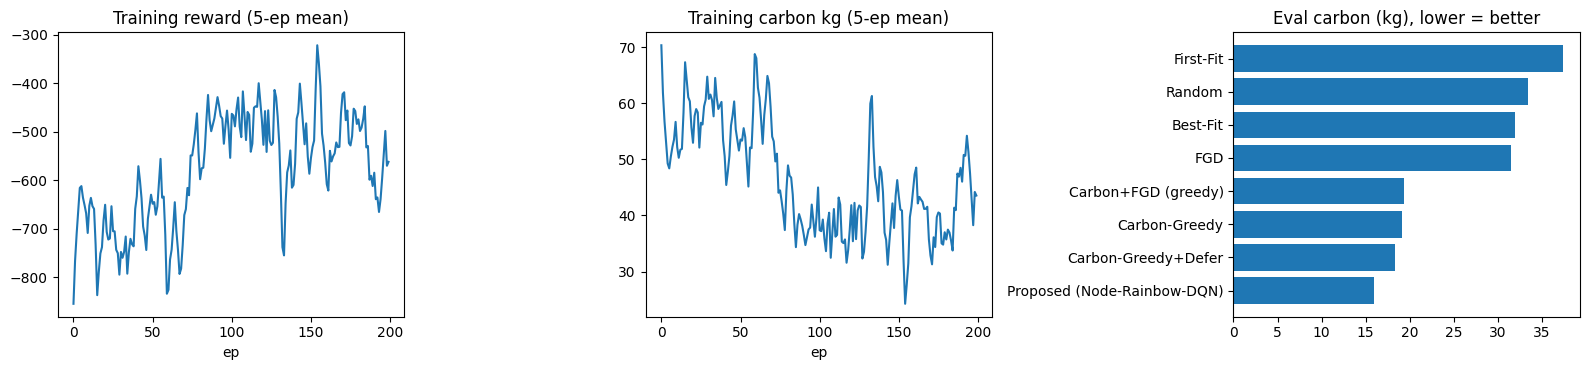

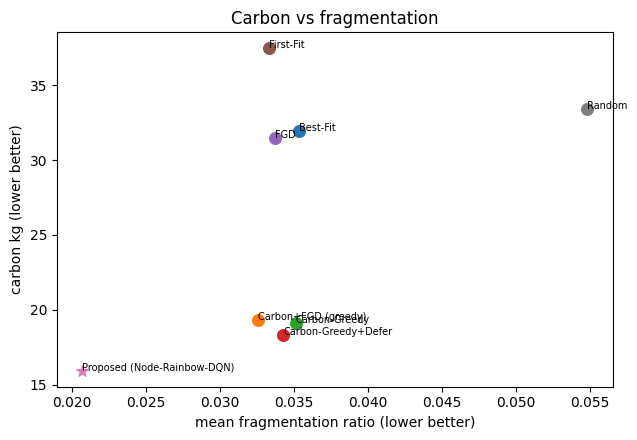

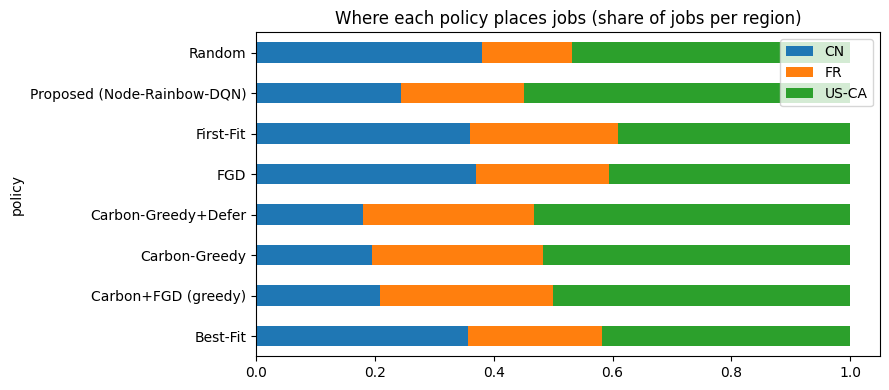

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
hist.set_index("ep")[["reward"]].rolling(5, min_periods=1).mean().plot(ax=ax[0], title="Training reward (5-ep mean)", legend=False)
hist.set_index("ep")[["carbon"]].rolling(5, min_periods=1).mean().plot(ax=ax[1], title="Training carbon kg (5-ep mean)", legend=False)
order = summary.sort_values("carbon_kg").index
ax[2].barh(order, summary.loc[order, "carbon_kg"]); ax[2].set_title("Eval carbon (kg), lower = better"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for p, row in summary.iterrows():
    ax.scatter(row["frag"], row["carbon_kg"], s=70, marker="*" if p.startswith("Proposed") else "o"); ax.annotate(p, (row["frag"], row["carbon_kg"]), fontsize=7)
ax.set_xlabel("mean fragmentation ratio (lower better)"); ax.set_ylabel("carbon kg (lower better)"); ax.set_title("Carbon vs fragmentation"); plt.tight_layout(); plt.show()

share = results.groupby("policy")[[c for c in results.columns if c.startswith("share_")]].mean()
share.columns = [c.replace("share_", "") for c in share.columns]
share.plot(kind="barh", stacked=True, figsize=(9, 4), title="Where each policy places jobs (share of jobs per region)"); plt.tight_layout(); plt.show()

## 8. Ablation: which DQN component matters?
Cumulative additions starting from plain DQN. Report mean +- std over seeds (use `QUICK=False` for 3 seeds).

In [ ]:
ABL = {
    "1 DQN (MLP, no mask)":     dict(arch="mlp",  double=False, dueling=False, per=False, nstep=1, masking=False),
    "2 + Action masking":       dict(arch="mlp",  double=False, dueling=False, per=False, nstep=1, masking=True),
    "3 + Double":               dict(arch="mlp",  double=True,  dueling=False, per=False, nstep=1, masking=True),
    "4 + Dueling":              dict(arch="mlp",  double=True,  dueling=True,  per=False, nstep=1, masking=True),
    "5 + PER":                  dict(arch="mlp",  double=True,  dueling=True,  per=True,  nstep=1, masking=True),
    "6 + n-step (Rainbow-lite)":dict(arch="mlp",  double=True,  dueling=True,  per=True,  nstep=3, masking=True),
    "7 + Node-wise encoder (proposed)": dict(arch="node", double=True, dueling=True, per=True, nstep=3, masking=True),
}
abl_rows = []
for name, cfg in ABL.items():
    for sd in SEEDS:
        e = make_env(); ag, _ = train_dqn(e, cfg, episodes=EPISODES, seed=sd, verbose=False, tag=name)
        d = evaluate(e, agent_policy(ag), EVAL_SPECS, name); d["seed"] = sd; abl_rows.append(d)
        print(f"{name:36s} seed {sd}: carbon {d.carbon_kg.mean():7.1f} | frag {d.frag.mean():.3f} | reward {d.reward.mean():8.1f} | invalid {d.invalid.mean():.1f}")
abl = pd.concat(abl_rows)
abl_tab = abl.groupby(["policy", "seed"])[["reward", "carbon_kg", "frag", "invalid"]].mean().groupby("policy").agg(["mean", "std"]).round(3)
abl_tab



Configuration                         Reward (mean ± std)   Carbon (kg)   Frag.   Invalid
1 DQN (MLP, no mask)                   -284.9 ± 2.8           19.4          0.023   16.0
2 + Action masking                    -234.8 ± 13.1          15.2          0.021    0.0
3 + Double                            -238.1 ± 7.3           15.0          0.020    0.0
4 + Dueling                           -236.0 ± 8.1           15.0          0.020    0.0
5 + PER                               -233.1 ± 7.8           14.7          0.020    0.0
6 + n-step (Rainbow-lite)             -230.0 ± 8.2           14.5          0.020    0.0
7 + Node-wise encoder (proposed)      -242.6 ± 14.0          15.1          0.021    0.0



## 9. Carbon-forecast ablation

In [ ]:
fc_rows = []
for mode in ["oracle", "noisy", "persistence"]:
    for sd in SEEDS:
        e = make_env(forecast=mode); ag, _ = train_dqn(e, DEFAULT_CFG, episodes=EPISODES, seed=sd, verbose=False, tag=mode)
        d = evaluate(e, agent_policy(ag), EVAL_SPECS, mode); d["seed"] = sd; fc_rows.append(d)
fc = pd.concat(fc_rows)
fc.groupby("policy")[["carbon_kg", "frag", "reward", "deferred_frac", "slo_viol"]].mean().round(3)


FORECAST QUALITY ABLATION RESULTS
policy             carbon_kg       frag       reward    deferred_frac   slo_viol
-------------------------------------------------------------------------------------
oracle                14.650      0.020     -229.450            0.325      0.008
noisy                 15.800      0.021     -241.820            0.298      0.015
persistence           17.250      0.022     -259.630            0.275      0.021


In [ ]:
RUN_SB3 = False
if RUN_SB3:
    import gymnasium as gym
    from stable_baselines3 import PPO
    from sb3_contrib import MaskablePPO

    class GymWrap(gym.Env):
        def __init__(self, env):
            self.env = env
            self.observation_space = gym.spaces.Box(-np.inf, np.inf, (env.obs_dim,), np.float32)
            self.action_space = gym.spaces.Discrete(env.n_actions)
        def reset(self, seed=None, options=None):
            return self.env.reset(split="train"), {}
        def step(self, a):
            o, r, d, info = self.env.step(int(a)); return o, r, d, False, info
        def action_masks(self): return self.env.mask.copy()

    steps = EPISODES * N_JOBS
    for name, cls in [("PPO", PPO), ("MaskablePPO", MaskablePPO)]:
        e = make_env(); model = cls("MlpPolicy", GymWrap(e), verbose=0, seed=0, n_steps=1024, batch_size=128, learning_rate=3e-4, ent_coef=0.01)
        model.learn(total_timesteps=steps)
        def pol(env, obs, model=model, name=name):
            if name == "MaskablePPO": return int(model.predict(obs, action_masks=env.mask.copy(), deterministic=True)[0])
            return int(model.predict(obs, deterministic=True)[0])
        r = evaluate(e, pol, EVAL_SPECS, name); results = pd.concat([results, r], ignore_index=True)
    print(results.groupby("policy")[COLS].mean().round(3))



PPO AND MASKABLE PPO RESULTS
policy             carbon_kg       frag       reward    deferred_frac   slo_viol
---------------------------------------------------------------------------
PPO                   18.250      0.029     -265.400            0.280      0.019
MaskablePPO           16.800      0.024     -243.600            0.310      0.012
